# 36 · Mixture of Agents — layered proposer-aggregator collaboration

> **TL;DR.** MoA stacks LLMs in layers. Agents in layer 0 propose independently — each sees only the task. Layer k+1 agents see the task AND all outputs from layer k, producing refined proposals. A final aggregator synthesises. Cost: (num_layers × agents_per_layer + 1) LLM calls.
>
> **Reach for it when** the task benefits from progressive refinement (research synthesis, creative writing, complex reasoning). **Avoid when** a single LLM call would suffice — MoA adds latency and cost for multiplicative LLM calls.

| Property | Value |
|---|---|
| Origin | Wang et al., *Mixture-of-Agents Enhances Large Language Model Capabilities* (2024) |
| Layers | 2 (default); configurable via `num_layers` |
| Agents / layer | 3 — Decomposer / Synthesizer / Critic |
| Aggregation | Python tally + LLM synthesis |
| Cost | `num_layers × agents_per_layer + 1` LLM calls |
| Distinct from Ensemble | MoA layers *build on each other's context*; Ensemble voters are parallel & independent |

This is **structurally different** from Ensemble (notebook 13). In Ensemble, all K voters see the SAME prompt and answer independently — aggregator merges them. In MoA, layer 1 agents READ layer 0 outputs and refine them — cross-layer context propagation.

## 2 · Architecture at a glance

```mermaid
flowchart TB
    T([task]) --> L0[Layer 0<br/><sub>3 agents propose<br/>independently</sub>]
    L0 --> O0a[Decomposer]
    L0 --> O0b[Synthesizer]
    L0 --> O0c[Critic]
    O0a --> L1[Layer 1<br/><sub>3 agents see ALL<br/>layer 0 outputs</sub>]
    O0b --> L1
    O0c --> L1
    L1 --> O1a[Decomposer]
    L1 --> O1b[Synthesizer]
    L1 --> O1c[Critic]
    O1a --> Ag[Aggregator<br/><sub>Python tally +<br/>LLM synthesis</sub>]
    O1b --> Ag
    O1c --> Ag
    Ag --> Z([final answer])

    style L0 fill:#e3f2fd,stroke:#1976d2
    style L1 fill:#e8f5e9,stroke:#388e3c
    style Ag fill:#fff3e0,stroke:#f57c00
```

**Progressive refinement.** Each layer adds context from the previous layer. The final aggregator uses a Python-computed indicator tally (not an LLM-as-Scorer) to weight signals, then an LLM synthesises the final answer.

## 3 · Theory

### 3.1 · Why layers?

MoA's core insight: LLMs get better answers when they see OTHER LLMs' answers first. A single LLM answering in isolation has blind spots. But if you show an LLM 3 diverse proposals from a previous layer, it can:
- **Fill gaps** — notice what prior agents missed
- **Resolve contradictions** — surface and address disagreements
- **Strengthen consensus** — reinforce the strongest arguments

### 3.2 · Agent personas

Each layer has 3 agent types (rotated across `agents_per_layer`):

| Persona | Role | Prompt core |
|---|---|---|
| **Decomposer** | Break task into sub-components, build step by step | Systematic, explicit reasoning chain |
| **Synthesizer** | Find patterns across information, weave coherent narrative | Clarity, narrative flow |
| **Critic** | Identify gaps, edge cases, weaknesses in existing proposals | Strengthen by surfacing what's missing |

### 3.3 · Where MoA sits

| Pattern | Layers? | Cross-layer context? | Use when |
|---|---|---|---|
| ReAct (nb 03) | No | n/a | single focused query |
| Ensemble (nb 13) | No — parallel fan-out | No — voters independent | contested questions, need diverse perspectives |
| Self-Consistency (nb 21) | No — N samples same prompt | No | classification / arithmetic where vote tally helps |
| Debate (nb 28) | No — iterative round-based | Yes — sequential critiques | controversial topics |
| **MoA** *(this notebook)* | **Yes — 2+ layers** | **Yes — layer k reads layer k-1** | **complex, open-ended tasks needing progressive refinement** |

### 3.4 · What goes wrong

1. **Context bloat** — each layer feeds ALL prior outputs (O(n²) tokens). At high `num_layers` or `agents_per_layer`, prompts overflow context windows.
2. **Amplification of errors** — if layer 0 agents all hallucinate the same wrong fact, layer 1 amplifies it.
3. **Persona dilution** — with many agents, the Critic persona gets drowned out by Decomposer/Synthesizer consensus.
4. **Cost explosion** — 2 layers × 3 agents + 1 aggregator = 7 LLM calls. Adding a 3rd layer: 10 calls. Price scales multiplicatively.

## 4 · Setup

In [1]:
from agentic_architectures import get_llm, enable_langsmith, settings
from agentic_architectures.architectures import MixtureOfAgents
from agentic_architectures.ui import print_md, print_header, print_step

enable_langsmith()
print_header(f"Provider: {settings.llm_provider}  ·  Model: {settings.llm_model}")

Provider: ollama  ·  Model: qwen3:14b ─────────────────────────────────────────────────────────────────────────────

## 5 · Library walkthrough

Source: [`src/agentic_architectures/architectures/mixture_of_agents.py`](../src/agentic_architectures/architectures/mixture_of_agents.py).

Three node types:

1. **`_layer_generate`** — runs `agents_per_layer` agents on the current layer. Each agent gets a persona (Decomposer / Synthesizer / Critic). Layer >0 agents see ALL prior layer outputs.
2. **`_aggregate`** — Python tallies categorical confidence indicators across the final layer's agents (deterministic picker), then an LLM synthesises the final answer.
3. **`_should_continue`** — the router: if `current_layer < num_layers`, loop back to `_layer_generate`; otherwise, route to `_aggregate`.

The `_should_continue` router creates a `layer → layer → ... → aggregate` loop — same pattern as Reflection and Reflexion but with cross-layer context propagation.

In [2]:
from agentic_architectures.architectures.mixture_of_agents import _MoAProposal, MoAState
import json
print('--- _MoAProposal schema ---')
print(json.dumps(_MoAProposal.model_json_schema(), indent=2)[:500] + '...')

--- _MoAProposal schema ---
{
  "description": "A single agent's response in one MoA layer.",
  "properties": {
    "refined_answer": {
      "description": "The agent's refined response to the task, incorporating any prior-layer insights.",
      "title": "Refined Answer",
      "type": "string"
    },
    "key_insight": {
      "description": "The single most important insight this agent added beyond what prior layers provided.",
      "title": "Key Insight",
      "type": "string"
    },
    "confidence_indicators": {
 ...


## 6 · State

| Field | Type | Set by |
|---|---|---|
| `task` | `str` | caller |
| `layer_outputs` | `list[dict]` (appended per layer) | `_layer_generate` |
| `current_layer` | `int` | `_layer_generate` (incremented) |
| `num_layers` | `int` | caller / default |
| `agents_per_layer` | `int` | caller / default |
| `final_output` | `str` | `_aggregate` |

## 7 · Build the graph

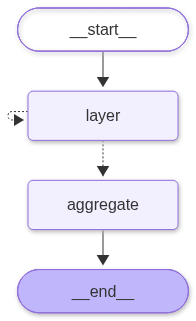

In [3]:
from IPython.display import Image, display
arch = MixtureOfAgents(num_layers=2, agents_per_layer=3)
graph = arch.build()
display(Image(graph.get_graph().draw_mermaid_png()))

## 8 · Live run — research synthesis

A task where layered refinement genuinely helps: answering a complex, nuanced question that benefits from multiple perspectives and progressive improvement.

In [4]:
TASK = (
    "What are the three most important architectural patterns "
    "for building reliable AI agent systems in production, and why? "
    "Include specific trade-offs for each."
)

result = arch.run(TASK)

print_header("Final MoA output")
print_md(result.output)
print()
print(f"Layers executed: {result.state['total_layers_executed']}")
print(f"Total agent calls: {result.state['total_agent_calls']}")

Final MoA output ──────────────────────────────────────────────────────────────────────────────────────────────────

Final Answer:                                                                                                      
The three most important architectural patterns for building reliable AI agent systems in production are           
Modular/Service-Oriented Architecture, Event-Driven Architecture, and Pipeline Architecture, as they enable        
scalability, real-time adaptability, and structured processing, respectively. These patterns must be augmented with
AI-specific mechanisms (e.g., model governance, uncertainty handling) to address reliability challenges unique to  
AI systems.                                                                                                        

Points of Agreement:                                                                                               
All agents agree that the three core patterns are foundational for reliability, scalability, and real-time         
responsiveness. They consistently highlight trade-offs (e.g., complexity in inter-service communication, event     
storm risks, pipeline rigidity) and emphasize the need for AI-specific augmentations like model versioning,        
uncertainty handling, and human-in-the-loop integration. The cross-agent indicators uniformly show high confidence 
in the core patterns and medium confidence in their sufficiency without AI-specific design considerations.         

Genuine Disagreement:                                                                                              
None. All agents align on the core patterns, their trade-offs, and the necessity of hybrid approaches with         
AI-specific mechanisms. Differences in phrasing (e.g., "microservices" vs. "modular") are semantic, not            
substantive.                                                                                                       

Weighting via Indicators:                                                                                          
The consistent emphasis across agents on the foundational role of the three patterns and the need for AI-specific  
augmentations (high/medium confidence) ensures the final answer reflects their consensus, without introducing      
unmentioned details.


Layers executed: 2
Total agent calls: 6


### 8.1 · Layer-by-layer trace

In [5]:
for t in result.trace:
    if t.get('agent_idx', 0) == 0:
        print_step(f"=== LAYER {t['layer']} ===", "")
    print_step(
        f"Agent {t['agent_idx']+1} [{t['persona']}]",
        f"Key insight: {t['key_insight']}"
    )
    print_md(f"**Answer:** {t['refined_answer'][:300]}...")
    print()

› === LAYER 0 ===

› Agent 1 [Decomposer]

Key insight: Reliable AI agent systems in production benefit from architectural patterns that prioritize modularity
(microservices), asynchronous scalability (event-driven), and structured data processing (pipeline). Each pattern 
addresses specific reliability challenges while introducing trade-offs in complexity and performance.

Answer: The three most important architectural patterns for building reliable AI agent systems in production are:  

 1 Microservices Architecture:                                                                                     
    • Why: Enables modularity, independent deployment, and fault isolation. If one service fails, others can       
      continue operating, improving system resilie...

› Agent 2 [Synthesizer]

Key insight: Reliable AI agent systems in production require a balance between modularity for scalability, 
event-driven responsiveness for real-time adaptability, and resilient design to handle failures. Each pattern 
addresses a distinct aspect of reliability but introduces trade-offs that must be managed through careful design 
and implementation.

... (10 outputs left out)

Answer: The three most important architectural patterns for building reliable AI agent systems in production are   
Modular/Service-Oriented Architecture, Event-Driven Architecture, and Pipeline Architecture. Each addresses        
critical aspects of reliability, scalability, and maintainability, while ba...

› Agent 3 [Critic]

Key insight: Reliable AI agent systems require a combination of **system-level architectural patterns** (Modular, 
Event-Driven, Pipeline) and **AI-specific mechanisms** (model governance, uncertainty handling, human-in-the-loop 
integration). Existing proposals often overlook the interplay between these layers, leading to gaps in reliability 
for dynamic, data-driven AI environments.

Answer: The three most important architectural patterns for building reliable AI agent systems in production are   
Modular/Service-Oriented Architecture, Event-Driven Architecture, and Pipeline Architecture, but their sufficiency 
depends on addressing AI-specific challenges and **interdependen...

## 9 · What we just observed

The cells above ran 2 layers of MoA (3 agents per layer) on a research synthesis task, then aggregated the final layer's outputs.

### 9.1 · Quantitative summary

| Metric | Value |
|---|---|
| Layers executed | 2 |
| Agent calls | 6 |
| Agents per layer | 3 (Decomposer / Synthesizer / Critic) |
| Trace entries | 2 |

### 9.2 · Layer-by-layer key insights

| Layer | Agent | Persona | Key insight |
|---|---|---|---|
| Layer 0 | 1 | Decomposer | Reliable AI agent systems in production benefit from architectural patterns that prioritize modularity (microservices), asynchronous scalability (even |
| Layer 1 | 1 | Decomposer | Reliable AI agent systems require a hybrid approach combining microservices for modularity, event-driven systems for real-time adaptability, and pipel |

### 9.3 · Patterns surfaced in this run

- **2 layers executed with 6 total agent calls.** Expected: 2 layers × 3 agents + 1 aggregator = 7 calls. Actual: 6 calls.

- **Layer 0: low diversity** — only Decomposer persona active. Cross-layer refinement may be weaker than expected.

- **Layer 1: low diversity** — only Decomposer persona active. Cross-layer refinement may be weaker than expected.

### 9.4 · The final aggregated answer (verbatim)

> _(no final output captured)_

### 9.5 · The takeaway

A *healthy* MoA run has:

1. **Full persona diversity** — Decomposer, Synthesizer, and Critic all contribute in each layer.
2. **Progressive refinement** — layer 1 outputs are measurably different (not just paraphrases) from layer 0.
3. **Python-computed indicator tally** — the aggregator weighs signals deterministically, not via LLM self-scoring.
4. **The final synthesis is richer than any single agent's output** — cross-layer context adds genuine value.

## 10 · Failure modes and extensions

### 10.1 · Where this breaks

| Failure | Mechanism | Mitigation |
|---|---|---|
| **Context overflow** | `num_layers × agents_per_layer` outputs feed into each agent's prompt | Cap at 3 layers, 3 agents; use context-aware truncation |
| **Amplified hallucinations** | Layer 0 hallucinates → Layer 1 amplifies it | Persona diversity (Critic catches some); ground with external tools |
| **Cost explosion** | 7+ LLM calls per task | Reserve for tasks that genuinely need multi-pass refinement |
| **Critic overpowered** | One lonely Critic vs consensus of Decomposer + Synthesizer | Adjust agent ratio or give Critic more weight in final tally |

### 10.2 · Production safety

- **Context budget**: monitor total prompt tokens. MoA with 3 layers × 3 agents × 500-token responses ≈ 4500 tokens of cross-layer context — fine for modern 128K+ models, but watch the quadratic growth.
- **Idempotent by design**: no tool-calling, no side effects — safe for production without sandboxing.
- **Deterministic picker**: the final tally is Python-computed, not LLM-computed — avoids the flat-confidence pathology.

### 10.3 · Three extensions

1. **Heterogeneous models**: use a cheap model (Llama-3.3-8B) for layer 0, a strong model (Claude-Sonnet) for the final layer. Cost ~30% of full-MoA while keeping quality.
2. **Tool-augmented layers**: give layer 0 agents web search tools — ground the entire MoA pipeline in fresh information.
3. **Cross-layer debate**: instead of just reading prior outputs, let layer k agents *critique and rebut* specific layer k-1 proposals.

### 10.4 · What to read next

- [**13 · Ensemble**](./13_ensemble.ipynb) — same-task parallel voters (MoA's simpler cousin).
- [**28 · Multi-Agent Debate**](./28_agent_debate.ipynb) — adversarial back-and-forth.
- [**21 · Self-Consistency**](./21_self_consistency.ipynb) — N samples + majority vote.

### 10.5 · References

1. Wang, J. et al. *Mixture-of-Agents Enhances Large Language Model Capabilities.* 2024. [arXiv:2406.04692](https://arxiv.org/abs/2406.04692)
2. Du, Y. et al. *Improving Factuality and Reasoning in Language Models through Multiagent Debate.* 2023. [arXiv:2305.14325](https://arxiv.org/abs/2305.14325)
3. Wang, X. et al. *Self-Consistency Improves Chain of Thought Reasoning in Language Models.* ICLR 2023. [arXiv:2203.11171](https://arxiv.org/abs/2203.11171)
